<a href="https://colab.research.google.com/github/juandiego-guerrero/Problem-Set-1-Econ_3916_PS1.ipynb/blob/main/ps1_starter_ipynb_JD_10_06.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS1 — The Cost of Living Brief

**Starter notebook.** The Canvas assignment is the brief: read it first. This
notebook only gives you the structure, one heading per step in the order the
rubric grades them. Every cell that computes something is yours to write.

**Before you start**
1. *File › Save a copy in Drive*, and rename the copy `Econ 3916 PS1`.
2. Write every explanation in a **text cell**, not in `#` comments. A client
   reads this as a document.
3. **AI is not allowed in Phases 1–3.** You write the dictionaries, the loops,
   the data fetches and the interpretation yourself. Phase 4 is where AI is
   required.

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---
## Phase 1: Construct the Basket (30 pts)

### Step 1.1: Define the household (20 pts)

**Who is the household?** Describe one concrete household in a sentence or two:
who earns, how they get to work, what they spend on. Every later choice has to
be defensible for them.

A household is an fundamental group of individuals who live under the same house and make financial decisions regarding income, consumption, and allocation of resources. In a household, the primary earners are responsible to provide basic needs to a family, like health, education, food, safety, and other wants such as travelling, entertainment, or technologies.

> ### New idiom — a list of dictionaries
>
> A **dictionary** holds values under names: `{"Item": "Rent", "weight": 0.35}`.
> `item["weight"]` reads a value back by its name.
>
> A **list of dictionaries** is one dictionary per row, in square brackets and
> separated by commas. It is how you store a small table by hand:
>
> ```python
> fruit = [
>     {"name": "apple",  "price": 0.50},
>     {"name": "banana", "price": 0.25},
> ]
> for f in fruit:            # f is one dictionary at a time
>     print(f["name"], f["price"])
> ```
>
> Use the keys `Item`, `Price_2019`, `Price_2024` and `weight`: the Phase 4
> prompt assumes those names.

In [15]:
# At least six categories. Weights are shares of monthly spending and must sum to 1.0.
household_basket = [
    {"Item": "Milk", "Price_2019": 3.188, "Price_2024": 4.101, "weight": 0.10},
    {"Item": "Eggs", "Price_2019": 1.535, "Price_2024": 4.146, "weight": 0.10},
    {"Item": "Bread", "Price_2019": 1.363, "Price_2024": 1.912, "weight": 0.10},
    {"Item": "Ground Beef", "Price_2019": 3.862, "Price_2024": 5.605, "weight": 0.20},
    {"Item": "Gasoline", "Price_2019": 2.652, "Price_2024": 3.277, "weight": 0.30},
    {"Item": "Chicken", "Price_2019": 1.450, "Price_2024": 2.061, "weight": 0.20}
]

In [16]:
# Check: run this after filling in the basket
total_weight = sum(item["weight"] for item in household_basket)
print(f"{len(household_basket)} categories, weights sum to {total_weight:.4f}")

6 categories, weights sum to 1.0000


### Step 1.2: Build the index by hand (10 pts)

> ### New idiom — writing a function
>
> ```python
> def price_change(old, new):
>     """Percentage change from old to new."""
>     return (new - old) / old * 100
>
> price_change(2.00, 2.50)     # 25.0
> ```
>
> `def` names the function and its **parameters** (`old`, `new`). The body is
> indented. `return` hands the result back; without it the function gives back
> `None`. Inside the body, use the parameters, never the names of your own
> variables outside it, or the function only works on one dataset.

In [17]:
def laspeyres(basket, base_key, current_key):
    """Base-weighted price index for `basket`, with the base period = 100."""
    # index = 0
    # for item un basket:
    # index += item["weight"]*item[current_key]/item[base_key]

    return index * 100

In [18]:
def price_change(old, new):
    """Percentage change from old to new."""
    return (new - old) / old * 100

# 1. The unweighted average price change across categories
changes = [price_change(item["Price_2019"], item["Price_2024"]) for item in household_basket]
unweighted_avg = sum(changes) / len(changes)
print(f"Unweighted Average Price Change: {unweighted_avg:.2f}%")

# 2. Your weighted Laspeyres index
# Re-defining a clean laspeyres calculation locally to ensure it runs without relying on the broken cell above
def compute_laspeyres(basket, base_key, current_key):
    index_val = 0.0
    for item in basket:
        index_val += item["weight"] * (item[current_key] / item[base_key])
    return index_val * 100

laspeyres_index = compute_laspeyres(household_basket, "Price_2019", "Price_2024")
# To compare apples to apples, the index represents (New Basket Cost / Base Basket Cost) * 100.
# The percentage change implied by this weighted index is (laspeyres_index - 100)%
weighted_change = laspeyres_index - 100
print(f"Weighted Laspeyres Index: {laspeyres_index:.2f} (equivalent to a {weighted_change:.2f}% price increase)")

# 3. The gap between them
gap = unweighted_avg - weighted_change
print(f"Gap between unweighted average and weighted change: {gap:.2f} percentage points")

Unweighted Average Price Change: 58.31%
Weighted Laspeyres Index: 148.43 (equivalent to a 48.43% price increase)
Gap between unweighted average and weighted change: 9.88 percentage points


**Why do the two differ, and which would you defend to the client?**

I would defend the Laspeyres index to the client. The client is asking what workers actually face in terms of prices, and the question is about the cost of a realistic cost of a basket, and not the average movement of individual prices within the basket. Laspeyres index uses the same method as the CPI, so the comparison isolates which is whose spending pattern the weights reflect.

The Unweighted Average Price change and the Weighted Laspeyres Index have differences in they way it is measured. Firstly, the unweighted average includes price, while the Laspeyres consider the price and what households actually buy. Further, the unweighted average answers the questions of how much did prices change on average, item by item. On the other hand, Laspeyres finds out how much more does the same basket cost now. The main difference is that unweighted average gives each of the six items equal importance, while Laspeyres index weights each item by the share of household spending.



---
## Phase 2: Bring in the Official Series (25 pts)

### Step 2.1: Find honest proxies (15 pts)

Fetch at least these four from FRED, plus any your household needs. Lab 2
showed how to read a FRED series from its CSV link, with no API key.

In [19]:
series_ids = ["CPIAUCSL", "CUSR0000SEHA", "CUSR0000SAF11", "CUSR0000SETA02", "APU00007471A"]

| Series | Why it is a fair proxy for my household | What it fails to capture |
|---|---|---|
| `CPIAUCSL` |It is a headline CPI for all urban consumers (typical basket):<br> the official benchmark the client says that overstates their worker's costs.|Workers at a regional employer likely spend larger amounts on food, housing, and gasoline than the national average,<br> so CPI can under or overstate their costs depending on the weight of each category.|
| `CUSR0000SEHA` |Tracks the rent paid by urban citizens along a period of time, <br>and rent is the largest weight category in the basket.  |It is a national average that misses local rent in the employer's region, excludes mortgages costs,<br> and it is not in my basket, so my index does not consider housing.  |
| `CUSR0000SAF11` |Tracks the price of food at a home in the US for urban consumers,<br> and food one of the most important goods in a basket and what I explained in my definition. |Again, it is a national average and excludes the employer's region,<br> and in my basket there are specific goods selected, so these values would despair my index. |
| `CUSR0000SETA02` |Tracks used vehicles prices, which matter to individuals and household,<br> mostly which depend on a car to commute to a regional employer or to move from one place to another. |It is not in my basket, it reflects an occasional large purchase rather than a monthly cost like gasoline, <br>and it excludes those workers who commute on public transportation or other ways. |
| `APU00007471A` |Gasoline contains the largest weight in my selected index,<br> and it is a common good workers use in most cases to attend to an office. |Some workers may not travel by car, so the price of gasoline does not affect them at all,<br> and the gasoline is shown by the average price of gasoline, and not as an index.  |

### Step 2.2: Put them on the same footing (10 pts)

Rebase every series to 2019 = 100 and plot them on one chart with your
household index. The chart needs axis labels, a legend, and a title that states
a finding rather than naming the variables.

In [20]:
# Rebase to 2019 = 100
import pandas as pd

# Fetch each FRED series from its correct CSV link
frames = {}
for sid in series_ids:
  url = f"https://fred.stlouisfed.org/graph/fredgraph.csv?id={sid}"
  df = pd.read_csv(url,parse_dates=[0], index_col=0, na_values=".")
  frames[sid] = df.iloc[:,0].astype(float)
fred = pd.DataFrame(frames)

# Annual averages, each year lines up with the yearly prices in the basket
annual = fred.resample("YE").mean()
annual.index = annual.index.year
annual = annual.loc[2019:2024]

# Rebase: divide every value by its 2019 value, times 100
rebased = annual / annual.loc[2019] * 100

# Calculate Laspeyres index for 2024 (Base 2019 = 100) robustly inline
laspeyres_2024 = 0.0
for item in household_basket:
  laspeyres_2024 += item["weight"] * (item["Price_2024"] / item["Price_2019"])
laspeyres_2024 *= 100

# Household index has only two points: the base year and 2024
household = pd.Series ({2019:100.0, 2024:laspeyres_2024}, name="Household")

# Plot
rebased = pd.concat([rebased, household], axis=1)
rebased.round(1)


,CPIAUCSL,CUSR0000SEHA,CUSR0000SAF11,CUSR0000SETA02,APU00007471A,Household
2019,100.0,100.0,100.0,100.0,100.0,100.0
2020,101.3,103.1,103.5,103.2,83.1,NaN
2021,106.0,105.4,107.1,130.6,116.1,NaN
2022,114.5,111.8,119.3,147.3,155.3,NaN
2023,119.2,120.7,125.3,136.8,139.7,NaN
2024,122.7,126.9,126.8,128.7,132.6,148.4


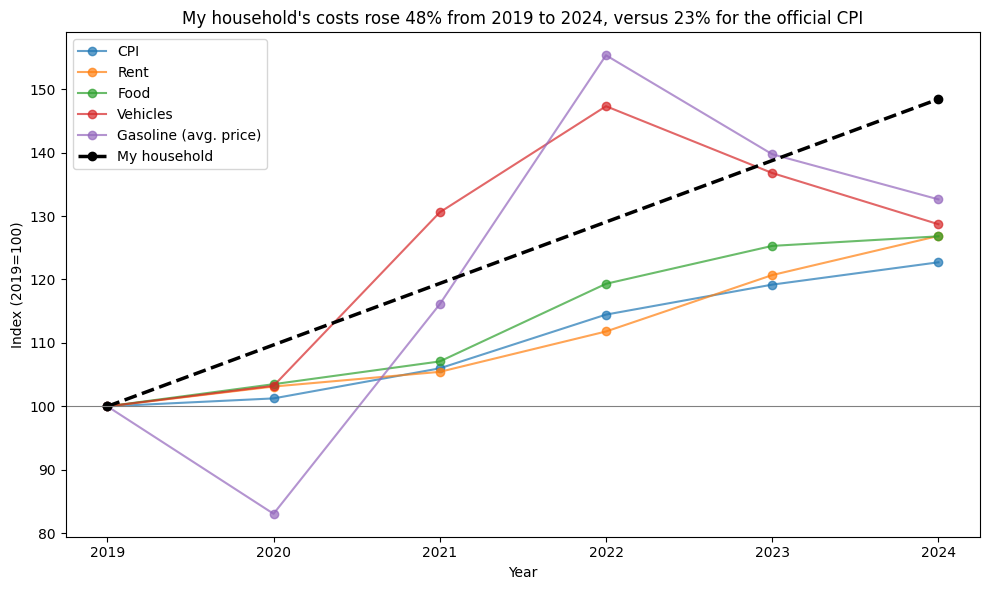

In [21]:
# One chart: every rebased series, plus your household index
import matplotlib.pyplot as plt

labels = {
    "CPIAUCSL": "CPI",
    "CUSR0000SEHA": "Rent",
    "CUSR0000SAF11": "Food",
    "CUSR0000SETA02": "Vehicles",
    "APU00007471A" : "Gasoline (avg. price)",
}

fig, ax = plt.subplots(figsize=(10,6))
for sid in rebased.columns:
  # Only plot FRED series in this loop; skip "Household Index" as it is plotted separately
  if sid in labels:
    ax.plot(rebased.index, rebased[sid], marker="o", alpha=0.7, label=labels[sid])

ax.plot(household.index, household.values, "o--", color="black",
        linewidth=2.5, label="My household ")
ax.axhline(100, color="grey", linewidth=0.8)

hh = household[2024] - 100
cpi = rebased.loc[2024, "CPIAUCSL"] - 100
ax.set_title(f"My household's costs rose {hh:.0f}% from 2019 to 2024, "
             f"versus {cpi:.0f}% for the official CPI")
ax.set_xlabel("Year")
ax.set_ylabel("Index (2019=100)")
ax.legend()
plt.tight_layout()
plt.show()

---
## Phase 3: What the Series Will and Will Not Let You Compare (20 pts)

### Step 3.1: Audit before you analyse (6 pts)

> ### A tool you have not used yet — a regular monthly grid
>
> `s.asfreq("MS")` puts a date-indexed series on one row per month (`"MS"` =
> month start). Any month the series skipped appears as a missing value, so
> `s.asfreq("MS").isna().sum()` counts the gaps. Report the count whatever it
> is; if it is not zero, list the missing months.

In [22]:
# First observation, last observation, frequency and missing months, for every series
audit = []
for sid in fred.columns:
  s = fred[sid].dropna()
  monthly = s.asfreq("MS")
  missing = monthly[monthly.isna()].index
  gap_days = s.index.to_series().diff().dt.days.median()

  audit.append({
      "Series":sid,
      "First": s.index.min().strftime("%Y-%m"),
      "Last": s.index.max().strftime("%Y-%m"),
      "Frequency": "Monthly" if 28 <= gap_days <= 31 else f"~{gap_days:.0f}days",
      "Missing months": len(missing),
      "Which months": ", ".join(missing.strftime("%Y-%m")) or "None"
     })

  audit_table = pd.DataFrame(audit).set_index("Series")
  audit_table

| Series | First | Last | Frequency | Missing months |
|---|---|---|---|---|
|CPIAUCSL|1947-01|2026-08|Monthly|2025-10|
|CUSR0000SEHA|1981-01|2026-08|Monthly|2025-10|
|CUSR0000SAF11|1952-01|2026-08|Monthly|2025-10|
|CUSR0000SETA02|1953-01|2026-08|Monthly |0 |
|APU00007471A|1978-01|2026-08|Monthly|2025-10|

### Step 3.2: The sample you actually have (8 pts)

Report three numbers: when the common sample starts, how many months long it
is, and how many months of your longest series it discards. Then compute your
headline comparison twice: over each series' full history, and over the common
sample only.

In [23]:
# Start dates side by side, and the common sample
starts = pd.DataFrame({
    "Start":fred.apply(lambda s: s.first_valid_index().strftime("%Y-%m")),
    "End": fred.apply(lambda s: s.last_valid_index().strftime("%Y-%m")),
    "Months of data": fred.count(),
})
print(starts, "\n")

common = fred.dropna()  # keep only months where every series has
longest = fred.count().idxmax()  # the series with the most observations
discarded = fred[longest].count() - len(common)

print(f"Common sample starts: {common.index.min():%Y-%m}")
print(f"Common sample length: {len(common)} months")
print(f"Months of {longest} discarded: {discarded}")

                  Start      End  Months of data
CPIAUCSL        1947-01  2026-08             955
CUSR0000SEHA    1981-01  2026-08             547
CUSR0000SAF11   1952-01  2026-08             895
CUSR0000SETA02  1953-01  2026-08             884
APU00007471A    1978-01  2026-08             583 

Common sample starts: 1981-01
Common sample length: 547 months
Months of CPIAUCSL discarded: 408


In [24]:
# Headline comparison: full history vs common sample
def annual_rate(s):
  """Average annual % change from the first to the last observation."""
  s = s.dropna()
  years = (s.index[-1] - s.index[0]).days / 365.25
  return  ((s.iloc[-1] / s.iloc[0]) ** (1 / years) - 1) * 100

comparison = pd.DataFrame ({
    "Full history (%/yr)": fred.apply(annual_rate),
    "Common sample (%/yr)": common.apply(annual_rate)
})
comparison["Difference"] = comparison["Full history (%/yr)"] - comparison["Common sample (%/yr)"]
comparison.round(2)

,Full history (%/yr),Common sample (%/yr),Difference
CPIAUCSL,3.51,2.99,0.52
CUSR0000SEHA,3.73,3.73,0.00
CUSR0000SAF11,3.18,2.75,0.43
CUSR0000SETA02,2.53,2.10,0.44
APU00007471A,4.05,2.74,1.31


**What restricting to the common sample assumes, and what not restricting assumes:**

Restricting to the common sample (1981-01 onward) assumes that comparing every series over the same years matters more than using all available data. It discards about 408 months of CPI history, meaning every series faces the same economic events. Not restricting will make users think that the different start dates do not distort the comparison. The full histories of CPI and gasoline include the high-inflation of the 1970s, and the oil shock, whole rent's history does not. The choice will change the conclusion.

In the full histories, gasoline outpace CPI, but over the common sample it rises more slowly. Rent's load over CPI also triples. The common sample is the fairer basis, because differences in it reflect prices, not time periods.

### Step 3.3: Somebody already made a decision for you (6 pts)

Pull the unadjusted twin of one series (`CPIAUCNS`, `CUUR0000SEHA`,
`CUUR0000SAF11` or `CUUR0000SETA02`) and plot the pair over the last five years.

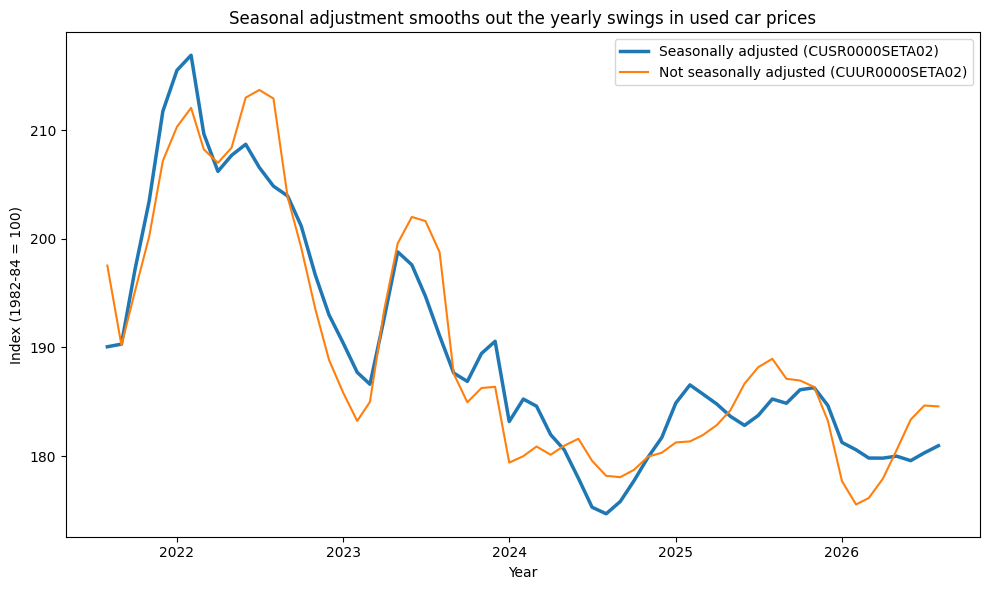

In [25]:
# Seasonally adjusted vs unadjusted, last five years
import matplotlib.pyplot as plt

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=CUUR0000SETA02"
nsa = pd.read_csv(url, parse_dates=[0], index_col=0, na_values=".").iloc[:,0].astype(float)

pair = pd.DataFrame ({
    "Seasonally adjusted (CUSR0000SETA02)": fred ["CUSR0000SETA02"],
    "Not seasonally adjusted (CUUR0000SETA02)": nsa,
})

end = pair.dropna().index.max()
pair = pair.loc[end - pd.DateOffset(years=5):end]

fig, ax = plt.subplots(figsize=(10,6))
ax.plot(pair.index, pair.iloc[:,0], linewidth=2.5, label=pair.columns[0])
ax.plot(pair.index, pair.iloc[:,1], linewidth=1.5, label=pair.columns[1])
ax.set_title("Seasonal adjustment smooths out the yearly swings in used car prices")
ax.set_xlabel("Year")
ax.set_ylabel("Index (1982-84 = 100)")
ax.legend()
plt.tight_layout()
plt.show()

**What does the gap between the two lines consist of? Which series belongs in this brief, and why?**

The gap between the two lines is the seasonal component: a pattern that repeats every year, with unadjusted used car prices running above the adjusted series in spring and summer below it in winter. Seasonal adjustment removes the pattern but keeps real market swings, such as the 2022 peak.

The unadjusted series belongs in this brief. It reflects prices workers paid, and what the Bureau of Labor Statistics recommends for wage escalation because it is never revised, and it matches our gasoline series, which is only published unadjusted (average prices). Since the brief compares full-year averages, where seasonal swings largely cancel out, the choice does not change the headline finding.

---
## Phase 4: AI Expansion (25 pts)

AI is now allowed and required.

### Task 4.1: The sensitivity surface (15 pts)

Run the P.R.I.M.E. prompt from the brief, then paste the code below and run it.

Base Laspeyres index (2019 = 100): 148.43

       Item  weight  price_relative  contribution_pts  share_of_change  sensitivity_per_10pp
       Eggs   0.100           2.701            17.010            0.351                13.519
   Gasoline   0.300           1.236             7.070            0.146                -3.551
       Milk   0.100           1.286             2.864            0.059                -2.199
      Bread   0.100           1.403             4.028            0.083                -0.905
    Chicken   0.200           1.421             8.428            0.174                -0.786
Ground Beef   0.200           1.451             9.026            0.186                -0.412

Most sensitive weight: Eggs (+13.52 index pts per +10pp)
Largest contributor to the change: Eggs (35.1% of the increase)


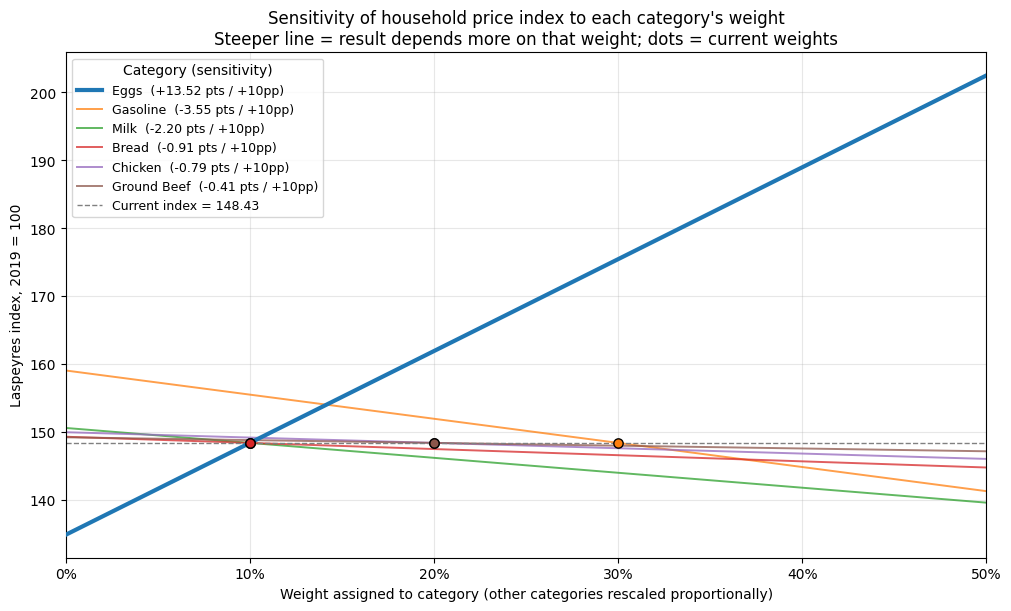

In [26]:
# Paste the AI's code here, run it, and correct it where it is wrong
"""
Weight-sensitivity analysis for a weighted Laspeyres household price index.

Expects `household_basket` to already exist in the session: a list of dicts with
keys Item, Price_2019, Price_2024 and weight (six spending categories).
"""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

if "household_basket" not in globals():
    raise NameError("Define `household_basket` before running this script.")

# ---------------------------------------------------------------------------
# 1. Base index
# ---------------------------------------------------------------------------
basket_df = pd.DataFrame(household_basket).reset_index(drop=True)

# ASSUMPTION: `weight` holds 2019 (base-period) expenditure shares or 2019
# spending amounts. Only then is this a Laspeyres index (equivalent to
# sum(P2024 * Q2019) / sum(P2019 * Q2019)). Weights from 2024 spending would
# give a different, non-Laspeyres index.
#
# Normalise weights to sum to 1. Report it rather than doing it silently, so a
# typo or rounding problem in the inputs is visible.
raw_weight_total = basket_df["weight"].sum()
if not np.isclose(raw_weight_total, 1.0):
    print(f"Note: weights summed to {raw_weight_total:.4f}; rescaled to sum to 1.\n")
basket_df["weight"] = basket_df["weight"] / raw_weight_total

# Laspeyres price relative for each category: how much the 2019 basket item
# costs at 2024 prices.
basket_df["price_relative"] = basket_df["Price_2024"] / basket_df["Price_2019"]

weights = basket_df["weight"].to_numpy()
relatives = basket_df["price_relative"].to_numpy()


def laspeyres_index(w, r):
    """Weighted Laspeyres index, 2019 = 100."""
    return 100 * np.dot(w, r)


base_index = laspeyres_index(weights, relatives)

# ---------------------------------------------------------------------------
# 2. Sweep each category's weight from 0 to 0.5
# ---------------------------------------------------------------------------
weight_grid = np.linspace(0, 0.5, 51)


def sweep_category(k, grid):
    """
    Index values as category k's weight moves across `grid`, with every other
    category rescaled in proportion.

    WHY RENORMALISE THE OTHER WEIGHTS:
    Laspeyres weights are expenditure shares, so they must sum to 1. If we
    raised category k's weight to t and left the rest untouched, the weights
    would sum to more (or less) than 1 and the index would rise or fall simply
    because the "household" is spending more or less in total, not because
    prices changed. That mixes a scale effect into what should be a pure
    price-mix effect. Rescaling the others by (1 - t) / (sum of their current
    weights) keeps the total at 1 and also preserves their relative sizes to
    one another, so the only thing that changes is how much of the budget
    goes to k versus "everything else as currently composed".
    """
    others = np.arange(len(weights)) != k
    others_total = weights[others].sum()
    if np.isclose(others_total, 0):
        raise ValueError(f"Category {k} holds all the weight; cannot renormalise.")

    index_path = np.empty_like(grid)
    for i, t in enumerate(grid):
        w_new = weights.copy()
        w_new[k] = t
        w_new[others] = weights[others] * (1 - t) / others_total
        index_path[i] = laspeyres_index(w_new, relatives)
    return index_path


sweeps = {k: sweep_category(k, weight_grid) for k in range(len(basket_df))}

# ---------------------------------------------------------------------------
# 3. Sensitivity and contribution summary
# ---------------------------------------------------------------------------
# With proportional rescaling the index is exactly linear in t:
#     I(t) = 100 * [ t * r_k + (1 - t) * R_others ]
# where R_others is the weighted average relative of the other categories.
# So the slope is 100 * (r_k - R_others): sensitivity depends on how far a
# category's inflation sits from the rest of the basket, NOT on how big its
# weight currently is.
#
# WHAT HIGH SENSITIVITY TO ONE CATEGORY MEANS:
# If one line is much steeper than the others, the headline number rests
# heavily on getting that single weight right. Any error in it (stale survey
# data, a household that spends differently from the assumed profile, or
# substitution away from that category since 2019, which Laspeyres ignores)
# feeds almost directly into the result. The index is then less a summary of
# "household inflation" and more a statement about one category's price.
slopes = {k: (path[-1] - path[0]) / (weight_grid[-1] - weight_grid[0])
          for k, path in sweeps.items()}

basket_df["sensitivity_per_10pp"] = [slopes[k] * 0.10 for k in range(len(basket_df))]
basket_df["contribution_pts"] = 100 * weights * (relatives - 1)
total_change = base_index - 100
basket_df["share_of_change"] = (
    basket_df["contribution_pts"] / total_change if not np.isclose(total_change, 0) else np.nan
)

summary = (basket_df[["Item", "weight", "price_relative",
                      "contribution_pts", "share_of_change", "sensitivity_per_10pp"]]
           .assign(abs_sens=lambda d: d["sensitivity_per_10pp"].abs())
           .sort_values("abs_sens", ascending=False)
           .drop(columns="abs_sens"))

most_sensitive_k = summary.index[0]
largest_contributor_k = basket_df["contribution_pts"].abs().idxmax()

print(f"Base Laspeyres index (2019 = 100): {base_index:.2f}\n")
print(summary.to_string(index=False, float_format=lambda x: f"{x:.3f}"))
print(f"\nMost sensitive weight: {basket_df.loc[most_sensitive_k, 'Item']} "
      f"({basket_df.loc[most_sensitive_k, 'sensitivity_per_10pp']:+.2f} index pts per +10pp)")
print(f"Largest contributor to the change: {basket_df.loc[largest_contributor_k, 'Item']} "
      f"({basket_df.loc[largest_contributor_k, 'share_of_change']:.1%} of the increase)")
outside_sweep = basket_df.loc[basket_df["weight"] > weight_grid[-1], "Item"].tolist()
if outside_sweep:
    print(f"Note: current weight of {', '.join(outside_sweep)} exceeds 50%, "
          "so its current-weight marker is off the chart.")

# ---------------------------------------------------------------------------
# 4. Single chart
# ---------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")

for k in summary.index:  # legend ordered from most to least sensitive
    item = basket_df.loc[k, "Item"]
    is_top = k == most_sensitive_k
    line, = ax.plot(
        weight_grid, sweeps[k],
        linewidth=3.0 if is_top else 1.4,
        alpha=1.0 if is_top else 0.75,
        zorder=3 if is_top else 2,
        label=f"{item}  ({basket_df.loc[k, 'sensitivity_per_10pp']:+.2f} pts / +10pp)",
    )
    # Mark the category's actual weight (only if it falls inside the sweep).
    if weights[k] <= weight_grid[-1]:
        ax.scatter(weights[k], base_index, color=line.get_color(),
                   edgecolor="black", s=45, zorder=4)

ax.axhline(base_index, color="grey", linestyle="--", linewidth=1,
           label=f"Current index = {base_index:.2f}")
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1.0))
ax.set_xlim(weight_grid[0], weight_grid[-1])
ax.set_xlabel("Weight assigned to category (other categories rescaled proportionally)")
ax.set_ylabel("Laspeyres index, 2019 = 100")
ax.set_title("Sensitivity of household price index to each category's weight\n"
             "Steeper line = result depends more on that weight; dots = current weights")
ax.grid(alpha=0.3)
ax.legend(title="Category (sensitivity)", loc="best", fontsize=9)

fig.savefig("laspeyres_weight_sensitivity.png", dpi=200)
plt.show()

**What did the model get wrong, or get right in a way you had to check? Show the check.**

The initial prompt gave an appropiate response to get a graph that shows the comparison of the sensitivity of change. Lines clearly show the different categories, and the current index is the same as in part 1.2.

However, I discussed with the AI to check if the code was correct. The first correction was that the laspeyres weight sensitivity now tells when it rescales weight of any category. Next, it warns if a category exceeds the 50% of a basket weight. In my case, the values of each category do not exceed 50%, so it is just a measure to make sure data was appropiate.

### AI Transcript

**Date: 10.08**

**Model:**

The script laspeyres_weight_sensitivity.py runs straight after your household_basket cell. It uses numpy, pandas and matplotlib only, and I ran it with deprecation warnings set to raise errors; none fired. It prints a summary table, draws one chart with six lines (the steepest line is the most sensitive category, drawn in bold, and the legend is sorted by sensitivity), and saves the chart as a PNG for the deliverable.

Which category dominates your result: I can’t name it yet, because your basket’s prices and weights aren’t in this conversation. The script prints the answer on its last two lines. If you paste the output or the household_basket values here, I’ll interpret your actual numbers.

What to look for when you read the output

The script reports two different kinds of “dominance,” and they often point to different categories. In my test on placeholder data, they did:

Sensitivity (sensitivity_per_10pp) measures how far the index moves if the category’s weight is wrong by 10 percentage points. The renormalisation makes the index exactly linear in each weight, with slope equal to 100 × (the category’s price relative minus the rest of the basket’s average relative). So the most sensitive category is the one whose inflation is furthest from everything else. Its weight size doesn’t matter. In the test, Energy had only a 10% weight but the steepest line, because it rose 45% against roughly 20% for the rest of the basket.
Contribution (share_of_change) measures how much of the measured increase came from each category. It is weight × inflation, so large-weight categories usually lead here. In the test, that was Food.

What to tell a client

Report both kinds of dominance, and frame the sensitive one as a range around the headline figure:

“Prices for this household profile rose X% between 2019 and 2024. [Category A] accounts for Y% of that increase. The figure is most sensitive to the assumed share of spending on [Category B]: if the household actually spends 10 points more or less of its budget there, the index shifts by about ±Z points. We’d present the headline as X% with a range of roughly X−Z to X+Z.”

Three follow-ups make that message stronger:

Check the source and vintage of the sensitive weight. That single input carries the most risk, so it deserves the most scrutiny.
Show an index that excludes that category next to the headline. This lets the client see how much of the story belongs to one category.
Flag substitution bias. Laspeyres holds 2019 spending patterns fixed. If the sensitive category is also a fast riser, households have probably cut back on it, so the fixed-weight index likely overstates their real cost increase. That makes the true number more likely to fall in the lower half of the range.

**Fixed model:**

The updated laspeyres_weight_sensitivity.py includes all three fixes. It still passes the full verification and gives the same numbers as before.

I also need to correct one claim from my earlier answer. I said substitution bias makes the true number “more likely to fall in the lower half of the range.” That overstated things. The ±Z range measures uncertainty about the weight itself, while substitution bias is a separate, one-directional effect. The accurate version for a client is this: because Laspeyres holds 2019 spending patterns fixed, it tends to overstate the household’s cost-of-living increase. The overstatement is largest when the household has shifted spending away from the fastest-rising categories. That’s a reason to flag the headline as an upper-end estimate, not a claim about where the true value sits within the ±Z band.

Everything else stands, including the point that the most sensitive category is the one whose inflation is furthest from the rest of the basket, not necessarily the one with the biggest weight. I still need your actual household_basket values, or the script’s printed output, to say which category dominates your result.

### Task 4.2: The written finding (10 pts)

250 words at most, to the director. A number in the first sentence, no code,
and a confidence level.

Our model demonstrates household's cost rose by 48% between 2019 and 2024, roughly double the 23% rise in the oficial CPI. So the selected basket, evidence runs against the client's view that CPI overstates their worker's cost.

Eggs had the greateast increase. Eggs only represent 10% of the household's spending, but the price rose by 170%, so they account for 35% of the total increase (17.0 (eggs index increase) ÷ 48.4 (Laspeyres index increase) = 0.351). The result of the model is most sensitive to the eggs weight, each 10% points of spending shifted to 13.5 points, against other goods in the basket that have an average of 3.6 points.

The direction of the data holds regardless. Even if eggs are removed entirely from the basket, it still leaves a 35% increase.

However, the model contains some limits. The basket only covers food and gasoline, and does not consider rent, which rose by 27%, so it does not measure the full cost of living. Next, all the weights were fixed at 2019 spending, so if a household bought less eggs as prices spiked through 2024, the true increase is lower. Finally, a 10% egg share is high for most household, so the realistic figure sits near the bottom of the range.

**Recommendation:** report the increase as 35% to 42%, describe it as rose of food and fuel cosrs, and housing before presenting the model as a cost of living measure.

**Confidence:** Moderate / High

---
### Before you submit
- [ ] Every step above has output, and every explanation is in a text cell
- [ ] The AI Transcript names the model and the date
- [ ] *Runtime › Restart and run all* runs without errors
- [ ] Share link on Canvas; the same notebook in `Problem Set 1/` on GitHub